# Normalize sqY2H consensus scores

This script applies various QA/QC steps and then computes a normalized interaction score. For QA/QC we:

1.   Check whether 6 media controls on each mega-plate meet various condition-specific thresholds
2.   Check for autoactivation mating failures
3.   Adjust consensus score based on autoactivation score and filter if score invalid

In [124]:
import polars as pl 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [125]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_inputs = "../../../1_allele_collection/1_inputs"
meta_outputs = "../../../1_allele_collection/3_outputs"

scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
max_score = 4
aa_id = '0.0'
rrs_id = 999999.0

In [126]:
def df_to_dict_variants(df):
    if isinstance(df, pl.DataFrame):
        df = df.to_pandas()
        
    if 'media_control' in df.columns:
        df = df[df['media_control'] == False].copy()
        
    scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
        
    if 'condition_name' in df.columns:
        df = df[df['condition_name'].isin(scoring_conditions)].copy()
    
    cols_to_keep = ['db_orf_id', 'ad_orf_id', 'db_mut_id', 'retest_batch']

    df = df[cols_to_keep].copy()

    df[['db_orf_id', 'ad_orf_id', 'db_mut_id']] = df[['db_orf_id', 'ad_orf_id', 'db_mut_id']].map(float).map(int)
        
    def filter_df(df):
        df = df[(df.ad_orf_id != 0) 
                & (df.db_mut_id != 999999)].copy()
        
        return df
    
    df = filter_df(df)
    
    df_dict = {}
    
    assay_array = ["VUSAPWT1B1","VUSAPWT1B2","VUSAPWT2B1","VUSAPWT6B1"]
    
    for retest_batch in assay_array:
        df_assay = df[df['retest_batch'] == retest_batch]
        df_dict[retest_batch] = {}
        for db_orf_id, df_db in df_assay.sort_values('db_orf_id').groupby('db_orf_id'):
            df_dict[retest_batch][db_orf_id] = {}
            for i, row in df_db.sort_values('db_mut_id').iterrows():
                db_mut_id = row['db_mut_id']
                ad_orf_id = row['ad_orf_id']
                if db_mut_id not in df_dict[retest_batch][db_orf_id].keys():
                    df_dict[retest_batch][db_orf_id][db_mut_id] = {ad_orf_id}
                else:
                    df_dict[retest_batch][db_orf_id][db_mut_id].add(ad_orf_id)
                    
    return df_dict

## Apply all QA/QC thresholds

In [127]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

In [128]:
scores = pd.read_csv(f"{outputs_dir}/2_raw_consensus_scores.csv") 

# Split into media controls
media_ctrls = scores[scores['media_control']]
scores = scores[~scores['media_control']]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'consensus_score']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls['score_in_bounds'] = media_ctrls['consensus_score'].between(media_ctrls['lower_bound'], media_ctrls['upper_bound'], inclusive='both')

# replace failure due to variable scoring (99999) with NaN to group with other technical failures
scores['consensus_score'] = scores['consensus_score'].replace(99999, np.nan)

# add IDs for groups used for filtering
scores = pl.DataFrame(scores)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores = scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group")
)

dict_before_qc = df_to_dict_variants(scores)

In [129]:
scores

ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,assay_id,db_group,db_condition_group,ppi_group
str,f64,str,f64,str,str,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str
"""6963.0""",null,"""7167.0""",216178.0,"""LWA""","""VUSAPWT1B1""",false,1.0,"""PLSCR3""","""AIPL1""","""Pro376Ser""","""1126C>T""","""ENSG00000129221""","""CEGS2""","""2_Benign""",null,2.0,"""AIPL1_Pro376Ser""","""1""","""7167.0_216178.0""","""7167.0_216178.0_LWA_VUSAPWT1B1""","""6963.0_7167.0_216178.0_VUSAPWT…"
"""201.0""",null,"""5431.0""",201911.0,"""LWH25""","""VUSAPWT1B2""",false,0.0,"""ZBED1""","""POLR1C""","""Arg279Trp""","""835C>T""","""ENSG00000171453""","""CEGS2""","""1_Pathogenic""",0.000039,2.0,"""POLR1C_Arg279Trp""","""1""","""5431.0_201911.0""","""5431.0_201911.0_LWH25_VUSAPWT1…","""201.0_5431.0_201911.0_VUSAPWT1…"
"""70073.0""",null,"""56822.0""",0.0,"""LWAH1""","""VUSAPWT2B1""",false,0.0,"""PLA2G10""","""GNE""",null,null,"""ENSG00000159921""",null,null,null,null,"""GNE""","""2""","""56822.0_0.0""","""56822.0_0.0_LWAH1_VUSAPWT2B1""","""70073.0_56822.0_0.0_VUSAPWT2B1"""
"""71001.0""",null,"""52920.0""",25125.0,"""LWAH1""","""VUSAPWT1B1""",false,0.0,"""UBQLN2""","""LITAF""","""Ala111Gly""","""332C>G""","""ENSG00000189067""","""RC4""","""1_Pathogenic""",null,2.0,"""LITAF_Ala111Gly""","""1""","""52920.0_25125.0""","""52920.0_25125.0_LWAH1_VUSAPWT1…","""71001.0_52920.0_25125.0_VUSAPW…"
"""55664.0""",null,"""4870.0""",215289.0,"""LWAH1""","""VUSAPWT1B2""",false,2.0,"""TRIM54""","""KRT6A""","""Ile462Asn""","""1385T>A""","""ENSG00000205420""","""CEGS2""","""1_Pathogenic""",null,2.0,"""KRT6A_Ile462Asn""","""1""","""4870.0_215289.0""","""4870.0_215289.0_LWAH1_VUSAPWT1…","""55664.0_4870.0_215289.0_VUSAPW…"
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""11381.0""",null,"""5673.0""",0.0,"""LWAH1""","""VUSAPWT6B1""",false,null,"""CD53""","""PLN""",null,null,"""ENSG00000198523""",null,null,null,null,"""PLN""","""6""","""5673.0_0.0""","""5673.0_0.0_LWAH1_VUSAPWT6B1""","""11381.0_5673.0_0.0_VUSAPWT6B1"""
"""7912.0""",null,"""4062.0""",201424.0,"""LW""","""VUSAPWT2B1""",false,4.0,"""CALN1""","""PLP1""","""Trp128Arg""","""382T>C""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PLP1_Trp128Arg""","""2""","""4062.0_201424.0""","""4062.0_201424.0_LW_VUSAPWT2B1""","""7912.0_4062.0_201424.0_VUSAPWT…"
"""13227.0""",null,"""12573.0""",2296.0,"""LWA""","""VUSAPWT1B1""",false,2.0,"""NEFL""","""DES""","""Asn342Asp""","""1024A>G""","""ENSG00000175084""","""Edgotyping3""","""1_Pathogenic""",null,1.0,"""DES_Asn342Asp""","""1""","""12573.0_2296.0""","""12573.0_2296.0_LWA_VUSAPWT1B1""","""13227.0_12573.0_2296.0_VUSAPWT…"


<Axes: title={'center': 'WT consensus manual scores'}, ylabel='Frequency'>

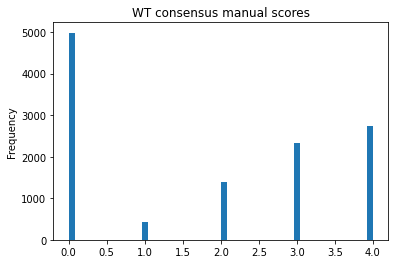

In [130]:
scores_pd = scores.to_pandas()
scores_pd[scores_pd['db_mut_id'] == 0].consensus_score.plot(kind='hist', bins=50, title='WT consensus manual scores')

In [131]:
scores_pd = scores.to_pandas()
scores_pd[
    (scores_pd.ad_orf_id == '12626.0') &
    (scores_pd.db_orf_id == '9905.0') #&
    # (scores_pd.db_mut_id == 215290)
    ]

,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,...,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,assay_id,db_group,db_condition_group,ppi_group
1008,12626.0,NaN,9905.0,216952.0,LWA,VUSAPWT1B2,False,0.0,CNTROB,PNKP,...,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWA_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2
2860,12626.0,NaN,9905.0,216950.0,LWAH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,...,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWAH1_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2
4012,12626.0,NaN,9905.0,216950.0,LW,VUSAPWT1B2,False,4.0,CNTROB,PNKP,...,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LW_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2
10784,12626.0,NaN,9905.0,216950.0,LWA,VUSAPWT1B2,False,0.0,CNTROB,PNKP,...,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWA_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2
14097,12626.0,NaN,9905.0,216952.0,LWH10,VUSAPWT1B2,False,3.0,CNTROB,PNKP,...,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWH10_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2
18778,12626.0,NaN,9905.0,216952.0,LW,VUSAPWT1B2,False,4.0,CNTROB,PNKP,...,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LW_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2
20170,12626.0,NaN,9905.0,216950.0,LWH1,VUSAPWT1B2,False,4.0,CNTROB,PNKP,...,ENSG00000039650,CEGS2,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWH1_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2
24595,12626.0,NaN,9905.0,0.0,LWH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,...,ENSG00000039650,None,None,NaN,NaN,PNKP,1,9905.0_0.0,9905.0_0.0_LWH1_VUSAPWT1B2,12626.0_9905.0_0.0_VUSAPWT1B2
25894,12626.0,NaN,9905.0,216952.0,LWAH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,...,ENSG00000039650,CEGS2,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWAH1_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2
26319,12626.0,NaN,9905.0,0.0,LWH10,VUSAPWT1B2,False,0.0,CNTROB,PNKP,...,ENSG00000039650,None,None,NaN,NaN,PNKP,1,9905.0_0.0,9905.0_0.0_LWH10_VUSAPWT1B2,12626.0_9905.0_0.0_VUSAPWT1B2


In [132]:
# Remove all db groups with the same allele if there was an autoactivation mating failure
aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 2)
                              .select("db_group")
                              .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))


dict_after_db_groups = df_to_dict_variants(scores)

# Remove all db-condition groups with the same allele if there was an autoactivation mating failure
aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))


dict_after_db_conditions = df_to_dict_variants(scores)

# remove mating failures - condition 1 shows no or little yeast growth
mating_failures = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 2)
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))

mating_failures_2 = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))

dict_after_mating = df_to_dict_variants(scores)

# Adjust consensus score based on autoactivation score
aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).rename({"consensus_score": "aa_score"})

# Remove autoactivation rows from the main scores df
# Add the aa_score to the dataframe, merged on the condition-specific db allele
scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group")

scores = scores.with_columns(
    (pl.col("consensus_score") - pl.col("aa_score")).alias("adjusted_score")
).filter(
    ~((pl.col("adjusted_score") <= 0) & (pl.col("aa_score") > 0))
)

dict_after_aa = df_to_dict_variants(scores)

In [133]:
print(aa_db_group_mating_failures)
print(len(aa_db_group_mating_failures))
print(aa_db_group_tech_failures)
print(len(aa_db_group_tech_failures))
print(mating_failures)
print(len(mating_failures))

['2920.0_214415.0', '100016069.0_2620.0', '13571.0_218098.0', '8416.0_216642.0', '100016069.0_2638.0', '100016069.0_2629.0', '100016069.0_2624.0', '281.0_29.0', '636.0_999999.0', '11435.0_999999.0', '100016069.0_2637.0', '55222.0_999999.0']
12
[]
0
['9501.0_5723.0_201962.0_VUSAPWT2B1', '3990.0_71001.0_205674.0_VUSAPWT2B1', '100069030.0_13295.0_218057.0_VUSAPWT2B1', '100069030.0_13295.0_218056.0_VUSAPWT2B1', '56547.0_52920.0_2667.0_VUSAPWT2B1', '14957.0_71001.0_205673.0_VUSAPWT2B1', '2842.0_2588.0_214279.0_VUSAPWT6B1', '56547.0_52920.0_2668.0_VUSAPWT2B1', '3068.0_5441.0_0.0_VUSAPWT2B1', '55690.0_5933.0_0.0_VUSAPWT2B1', '100069030.0_13295.0_218060.0_VUSAPWT2B1', '11539.0_2713.0_451.0_VUSAPWT6B1', '56547.0_52920.0_2682.0_VUSAPWT2B1', '56547.0_52920.0_2670.0_VUSAPWT2B1', '6337.0_13295.0_218057.0_VUSAPWT2B1', '54043.0_9905.0_0.0_VUSAPWT2B1', '7617.0_2651.0_214298.0_VUSAPWT6B1', '9230.0_2920.0_214424.0_VUSAPWT2B1', '6733.0_6733.0_0.0_VUSAPWT1B2', '100016069.0_100016069.0_2636.0_VUSAPWT1B1', 

In [134]:
scores_pd = scores.to_pandas()
scores_pd[
    (scores_pd.ad_orf_id == '12626.0') &
    (scores_pd.db_orf_id == '9905.0') #&
    # (scores_pd.db_mut_id == 215290)
    ]

,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,...,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,assay_id,db_group,db_condition_group,ppi_group,aa_score,adjusted_score
549,12626.0,NaN,9905.0,216952.0,LWA,VUSAPWT1B2,False,0.0,CNTROB,PNKP,...,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWA_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,0.0,0.0
1539,12626.0,NaN,9905.0,216950.0,LWAH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,...,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWAH1_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,0.0,0.0
5929,12626.0,NaN,9905.0,216950.0,LWA,VUSAPWT1B2,False,0.0,CNTROB,PNKP,...,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWA_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,0.0,0.0
7779,12626.0,NaN,9905.0,216952.0,LWH10,VUSAPWT1B2,False,3.0,CNTROB,PNKP,...,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWH10_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,0.0,3.0
11133,12626.0,NaN,9905.0,216950.0,LWH1,VUSAPWT1B2,False,4.0,CNTROB,PNKP,...,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWH1_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,0.0,4.0
14320,12626.0,NaN,9905.0,216952.0,LWAH1,VUSAPWT1B2,False,0.0,CNTROB,PNKP,...,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWAH1_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,0.0,0.0
15220,12626.0,NaN,9905.0,216952.0,LWH25,VUSAPWT1B2,False,3.0,CNTROB,PNKP,...,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWH25_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,0.0,3.0
20610,12626.0,NaN,9905.0,216950.0,LWH25,VUSAPWT1B2,False,3.0,CNTROB,PNKP,...,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWH25_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,0.0,3.0
36355,12626.0,NaN,9905.0,216950.0,LWH10,VUSAPWT1B2,False,4.0,CNTROB,PNKP,...,2_Benign,NaN,2.0,PNKP_Pro20Ser,1,9905.0_216950.0,9905.0_216950.0_LWH10_VUSAPWT1B2,12626.0_9905.0_216950.0_VUSAPWT1B2,0.0,4.0
37555,12626.0,NaN,9905.0,216952.0,LWH1,VUSAPWT1B2,False,4.0,CNTROB,PNKP,...,1_Pathogenic,NaN,2.0,PNKP_Glu326Lys,1,9905.0_216952.0,9905.0_216952.0_LWH1_VUSAPWT1B2,12626.0_9905.0_216952.0_VUSAPWT1B2,0.0,4.0


In [135]:
# split rrs & wt scores
rrs_scores = scores.filter(pl.col('db_mut_id') == rrs_id).filter(pl.col("condition_name") == "LWH1")
rrs_count_batch = rrs_scores.group_by(["retest_batch", "adjusted_score"]).agg(pl.len()).pivot(
    values="len", on="adjusted_score", index="retest_batch"
).select(["retest_batch", "0.0", "1.0", "2.0", "3.0", "4.0"])
print(rrs_count_batch)

wt_scores = scores.filter(pl.col('db_mut_id') == 0.0).filter(pl.col("condition_name") == "LWH1")
wt_count_batch = wt_scores.group_by(["retest_batch", "adjusted_score"]).agg(pl.len()).pivot(
    values="len", on="adjusted_score", index="retest_batch"
).select(["retest_batch", "0.0", "1.0", "2.0", "3.0", "4.0"])
print(wt_count_batch)

shape: (4, 6)
┌──────────────┬─────┬─────┬─────┬──────┬──────┐
│ retest_batch ┆ 0.0 ┆ 1.0 ┆ 2.0 ┆ 3.0  ┆ 4.0  │
│ ---          ┆ --- ┆ --- ┆ --- ┆ ---  ┆ ---  │
│ str          ┆ u32 ┆ u32 ┆ u32 ┆ u32  ┆ u32  │
╞══════════════╪═════╪═════╪═════╪══════╪══════╡
│ VUSAPWT6B1   ┆ 158 ┆ 2   ┆ 1   ┆ null ┆ 2    │
│ VUSAPWT1B1   ┆ 119 ┆ 1   ┆ 3   ┆ 2    ┆ 1    │
│ VUSAPWT1B2   ┆ 130 ┆ 4   ┆ 3   ┆ null ┆ null │
│ VUSAPWT2B1   ┆ 164 ┆ 2   ┆ 3   ┆ 4    ┆ null │
└──────────────┴─────┴─────┴─────┴──────┴──────┘
shape: (4, 6)
┌──────────────┬─────┬─────┬─────┬─────┬─────┐
│ retest_batch ┆ 0.0 ┆ 1.0 ┆ 2.0 ┆ 3.0 ┆ 4.0 │
│ ---          ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- │
│ str          ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32 │
╞══════════════╪═════╪═════╪═════╪═════╪═════╡
│ VUSAPWT2B1   ┆ 37  ┆ 11  ┆ 40  ┆ 86  ┆ 36  │
│ VUSAPWT1B2   ┆ 54  ┆ 19  ┆ 70  ┆ 215 ┆ 446 │
│ VUSAPWT1B1   ┆ 3   ┆ 4   ┆ 13  ┆ 19  ┆ 65  │
│ VUSAPWT6B1   ┆ 41  ┆ 6   ┆ 17  ┆ 127 ┆ 68  │
└──────────────┴─────┴─────┴─────┴─────┴─────┘


In [136]:
# Keep only scores that aren't RRS pairs
scores = scores.filter(pl.col('db_mut_id') != rrs_id)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

In [137]:
# read in sequence confirmation files
ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
    "swim_seq_validated": "seq_ad"
}).select([
    "ad_orf_id", "assay_id", "seq_ad"
])

db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "db_mut_id", "seq_db"])

db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
    "disease_orf_id": "db_orf_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "seq_db"]).with_columns(
    pl.lit(0).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "seq_db"])

db_seq = pl.concat([db_var_seq, db_ref_seq])
# print(db_seq)

## Add an extra QC step to check the sequence confirmation results
seq_confirm_res_df = pd.read_table(f"{meta_inputs}/seq_confirmation_results/VarChampSeqConfirmationResult.tsv")
# with pd.option_context('display.max_columns', None):
#     display(seq_confirm_res_df)

db_seq = pl.DataFrame(
    pd.merge(db_seq.to_pandas(), 
            seq_confirm_res_df[
                ["orf_id_wt","mutation_id_old","db_sequenced","db_sequence_confirmation_class"] ##"symbol","aa_change","nt_change","ccsb_mutation_id"
            ].rename({"orf_id_wt": "db_orf_id",
                      "mutation_id_old": "db_mut_id"}, axis=1), 
        on=["db_orf_id","db_mut_id"],
        how="left"
    )
)
print(db_seq)
# print(db_seq["db_sequenced"].unique())
# print(db_seq.filter(pl.col("db_sequenced")==0))

shape: (2_887, 5)
┌───────────┬───────────┬────────┬──────────────┬────────────────────────────────┐
│ db_orf_id ┆ db_mut_id ┆ seq_db ┆ db_sequenced ┆ db_sequence_confirmation_class │
│ ---       ┆ ---       ┆ ---    ┆ ---          ┆ ---                            │
│ i64       ┆ i64       ┆ str    ┆ f64          ┆ f64                            │
╞═══════════╪═══════════╪════════╪══════════════╪════════════════════════════════╡
│ 281       ┆ 727       ┆ NULL   ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 739       ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 13        ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 744       ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 763       ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ …         ┆ …         ┆ …      ┆ …            ┆ …                              │
│ 8514      ┆ 0         ┆ 1      ┆ null         ┆ null               

In [138]:
print(scores.shape)

(36407, 24)


In [139]:
# cast all to same format
scores = scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

# print(scores.filter(pl.col("db_mut_id")==0))

## Filter to only keep interactions where both ad and db are confirmed
## And also confirmed by the sequence confirmation results
valid_db_sequence_confirmation_class = [1., 2., 7., 99.]
scores = scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & (((pl.col("db_sequence_confirmation_class").is_in(valid_db_sequence_confirmation_class)) & (pl.col("db_sequenced").is_not_null())) | (pl.col("db_mut_id")==0))
)

## After sequence confirmation, we lost 25521 - 21895 = 3626 interactions
# print(scores.shape)
print(scores)

shape: (20_186, 28)
┌───────────┬───────────┬───────────┬───────────┬───┬────────┬────────┬──────────────┬─────────────┐
│ ad_orf_id ┆ ad_mut_id ┆ db_orf_id ┆ db_mut_id ┆ … ┆ seq_ad ┆ seq_db ┆ db_sequenced ┆ db_sequence │
│ ---       ┆ ---       ┆ ---       ┆ ---       ┆   ┆ ---    ┆ ---    ┆ ---          ┆ _confirmati │
│ i64       ┆ f64       ┆ i64       ┆ i64       ┆   ┆ str    ┆ str    ┆ f64          ┆ on_class    │
│           ┆           ┆           ┆           ┆   ┆        ┆        ┆              ┆ ---         │
│           ┆           ┆           ┆           ┆   ┆        ┆        ┆              ┆ f64         │
╞═══════════╪═══════════╪═══════════╪═══════════╪═══╪════════╪════════╪══════════════╪═════════════╡
│ 6963      ┆ null      ┆ 7167      ┆ 216178    ┆ … ┆ 1      ┆ 1      ┆ 1.0          ┆ 1.0         │
│ 70073     ┆ null      ┆ 56822     ┆ 0         ┆ … ┆ 1      ┆ 1      ┆ null         ┆ null        │
│ 55664     ┆ null      ┆ 4870      ┆ 215289    ┆ … ┆ 1      ┆ 1      ┆

In [140]:
dict_after_seq_1 = df_to_dict_variants(scores)

<Axes: title={'center': 'WT consensus manual scores'}, ylabel='Frequency'>

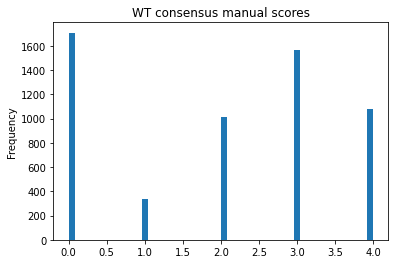

In [141]:
scores_pd = scores.to_pandas()
scores_pd[scores_pd['db_mut_id'] == 0].consensus_score.plot(kind='hist', bins=50, title='WT consensus manual scores')

In [142]:
# write out results
scores.write_csv(f"{outputs_dir}/3_normalized_qaqc_consensus_scores.csv")

## Calculate normalized scores

In [143]:
# prepare data to calculate normalized scores
normalized_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

normalized_scores = normalized_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    (pl.col("adjusted_score").sum() / (len(scoring_conditions)*max_score)).alias("normalized_score")
)

normalized_scores = normalized_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,assay_id
i64,i64,i64,str,f64,str
1198,9634,0,"""VUSAPWT2B1""",0.4375,"""2"""
5793,4062,201426,"""VUSAPWT2B1""",0.875,"""2"""
6490,2920,214409,"""VUSAPWT2B1""",0.4375,"""2"""
4621,4723,201744,"""VUSAPWT1B1""",1.0,"""1"""
52634,3535,201190,"""VUSAPWT6B1""",0.0625,"""6"""
…,…,…,…,…,…
4623,1256,214010,"""VUSAPWT1B2""",0.125,"""1"""
208,5066,0,"""VUSAPWT1B2""",0.5,"""1"""
56141,70497,3812,"""VUSAPWT1B1""",0.0625,"""1"""


In [144]:
# cast all to same format
normalized_scores = normalized_scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

normalized_scores = normalized_scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
normalized_scores = normalized_scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")


# Filter to only keep interactions where both ad and db are confirmed
normalized_scores = normalized_scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1")
)
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,assay_id,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class
i64,i64,i64,str,f64,str,str,str,f64,f64
1198,9634,0,"""VUSAPWT2B1""",0.4375,"""2""","""1""","""1""",null,null
5793,4062,201426,"""VUSAPWT2B1""",0.875,"""2""","""1""","""1""",1.0,1.0
6490,2920,214409,"""VUSAPWT2B1""",0.4375,"""2""","""1""","""1""",1.0,1.0
4621,4723,201744,"""VUSAPWT1B1""",1.0,"""1""","""1""","""1""",1.0,2.0
52634,3535,201190,"""VUSAPWT6B1""",0.0625,"""6""","""1""","""1""",1.0,1.0
…,…,…,…,…,…,…,…,…,…
4623,1256,214010,"""VUSAPWT1B2""",0.125,"""1""","""1""","""1""",1.0,1.0
208,5066,0,"""VUSAPWT1B2""",0.5,"""1""","""1""","""1""",null,null
56141,70497,3812,"""VUSAPWT1B1""",0.0625,"""1""","""1""","""1""",1.0,1.0


In [145]:
dict_after_seq_2 = df_to_dict_variants(normalized_scores)

In [146]:
# # map ad orfs ids to symbol

# horfeome_df = pd.read_csv(f"{meta_inputs}/horfeome_81_91_union.tsv", sep="\t")
# orf_to_symbol_dict = horfeome_df.set_index('orf_id')['symbol'].to_dict()

# # add a key for 0 as empty_AD
# orf_to_symbol_dict[0] = 'empty_AD'

# # update values where orfs are mapped to multiple symbols to only retain one previously used in the lab
# single_symbol_mapping_dict = {
#     1063: 'SMN2',
#     13954: 'AC005833.1',
#     55237: 'NBPF19',
#     2658: 'ZNF559-ZNF177',
#     1940: 'RBMY1F',
#     56585: 'CKMT1A',
#     2794: 'HBA1',
#     978: 'MAGEA2B',
#     70851: 'FAM25G',
#     3824: 'CKMT1A',
#     13813: 'CRYAA',
#     66: 'SMN1',
#     55944: 'KRTAP2-4',
#     13597: 'FAM187A',
#     56508: 'PRR20E',
#     100066377: 'TBC1D3G'
#     }


# for k, v in single_symbol_mapping_dict.items():
#     orf_to_symbol_dict[k] = v


# # apply mapping
# normalized_scores = normalized_scores.with_columns(
#     pl.col("ad_orf_id").replace_strict(orf_to_symbol_dict, default=None).alias("ad_symbol")
# )

In [147]:
# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

normalized_scores = normalized_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,assay_id,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,ad_symbol
i64,i64,i64,str,f64,str,str,str,f64,f64,str
1198,9634,0,"""VUSAPWT2B1""",0.4375,"""2""","""1""","""1""",null,null,"""TNFSF14"""
5793,4062,201426,"""VUSAPWT2B1""",0.875,"""2""","""1""","""1""",1.0,1.0,"""MS4A3"""
6490,2920,214409,"""VUSAPWT2B1""",0.4375,"""2""","""1""","""1""",1.0,1.0,"""PIAS2"""
4621,4723,201744,"""VUSAPWT1B1""",1.0,"""1""","""1""","""1""",1.0,2.0,"""KXD1"""
52634,3535,201190,"""VUSAPWT6B1""",0.0625,"""6""","""1""","""1""",1.0,1.0,"""CPLX4"""
…,…,…,…,…,…,…,…,…,…,…
4623,1256,214010,"""VUSAPWT1B2""",0.125,"""1""","""1""","""1""",1.0,1.0,"""KLHL12"""
208,5066,0,"""VUSAPWT1B2""",0.5,"""1""","""1""","""1""",null,null,"""ARRDC3"""
56141,70497,3812,"""VUSAPWT1B1""",0.0625,"""1""","""1""","""1""",1.0,1.0,"""KRT31"""


In [148]:
# Append metadata and write out file
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
})

normalized_scores = normalized_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,assay_id,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,f64,str,str,str,f64,f64,str,str,str,str,str,str,str,f64,f64,str
1198,9634,0,"""VUSAPWT2B1""",0.4375,"""2""","""1""","""1""",null,null,"""TNFSF14""","""CLDN19""",null,null,"""ENSG00000164007""",null,null,null,null,"""CLDN19"""
5793,4062,201426,"""VUSAPWT2B1""",0.875,"""2""","""1""","""1""",1.0,1.0,"""MS4A3""","""PLP1""","""Thr147Pro""","""439A>C""","""ENSG00000123560""","""CEGS2""","""1_Pathogenic""",null,null,"""PLP1_Thr147Pro"""
6490,2920,214409,"""VUSAPWT2B1""",0.4375,"""2""","""1""","""1""",1.0,1.0,"""PIAS2""","""GFAP""","""Glu205Lys""","""613G>A""","""ENSG00000131095""","""CEGS2""","""3_Conflicting""",null,1.0,"""GFAP_Glu205Lys"""
4621,4723,201744,"""VUSAPWT1B1""",1.0,"""1""","""1""","""1""",1.0,2.0,"""KXD1""","""TPM1""","""Asp230Asn""","""688G>A""","""ENSG00000140416""","""CEGS2""","""1_Pathogenic""",null,2.0,"""TPM1_Asp230Asn"""
52634,3535,201190,"""VUSAPWT6B1""",0.0625,"""6""","""1""","""1""",1.0,1.0,"""CPLX4""","""EMD""","""Met1Val""","""1A>G""","""ENSG00000102119""","""CEGS2""","""1_Pathogenic""",9.5000e-7,2.0,"""EMD_Met1Val"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
4623,1256,214010,"""VUSAPWT1B2""",0.125,"""1""","""1""","""1""",1.0,1.0,"""KLHL12""","""KLHL3""","""Cys164Phe""","""491G>T""","""ENSG00000146021""","""CEGS2""","""1_Pathogenic""",null,null,"""KLHL3_Cys164Phe"""
208,5066,0,"""VUSAPWT1B2""",0.5,"""1""","""1""","""1""",null,null,"""ARRDC3""","""BAG3""",null,null,"""ENSG00000151929""",null,null,null,null,"""BAG3"""
56141,70497,3812,"""VUSAPWT1B1""",0.0625,"""1""","""1""","""1""",1.0,1.0,"""KRT31""","""AGXT""","""Arg111Gln""","""332G>A""","""ENSG00000172482""","""Edgotyping3""","""1_Pathogenic""",0.000022,2.0,"""AGXT_Arg111Gln"""


In [149]:
normalized_scores.write_csv(f"{outputs_dir}/4_normalized_consensus_scores.csv")

In [150]:
normalized_scores_manual = normalized_scores

# Exploring qa/qc, dropped alleles

In [151]:
def describe_dict(df_dict):
    for assay_id in df_dict.keys():
        print(f"\tAssay ID: {assay_id}")
        n_db_orfs = len(df_dict[assay_id].keys())
        only_wt_count = 0
        db_list_wt = []
        n_wt = 0
        n_alleles = 0
        db_list_wt_with_var_wt = []
        db_list_wt_with_only_var = []
        ad_list = []
        
        for db_orf_id, db_mut_d in df_dict[assay_id].items():
            # if db_orf_id == 53798:
            #     print('53798')
            #     print(db_mut_d)
            
            if 0 in db_mut_d.keys():
                n_wt += 1
                n_alleles += len(db_mut_d.keys()) - 1
            else:
                n_alleles += len(db_mut_d.keys())
                
            if len(db_mut_d.keys()) == 1 and 0 in db_mut_d.keys():
                only_wt_count += 1
                db_list_wt.append(db_orf_id)
                
            if len(db_mut_d.keys()) > 1 and 0 in db_mut_d.keys():
                db_list_wt_with_var_wt.append(db_orf_id)
                
            if 0 not in db_mut_d.keys():
                db_list_wt_with_only_var.append(db_orf_id)
                
            ad_set = set()
            for db_mut_id, ad_orf_id_set in db_mut_d.items():
                for ad_orf_id in ad_orf_id_set:
                    ad_set.add(ad_orf_id)
                    
            ad_list.extend(list(ad_set))
            
            
        print(f"\t\tNumber of DB ORFs: {n_db_orfs}")        
        print(f"\t\tNumber of DB alleles: {n_alleles}")
        print(f"\t\tNumber of DB ORFs with WT: {n_wt}")
        print(f"\t\tNumber of DB ORFs with only WT: {only_wt_count}, {(only_wt_count/n_db_orfs)*100:.2f}%")
        print(f"\t\tNumber of DB ORFs with WT and alleles: {len(db_list_wt_with_var_wt)}, {(len(db_list_wt_with_var_wt)/n_db_orfs)*100:.2f}%")
        print(f"\t\tNumber of DB ORFs with only alleles: {len(db_list_wt_with_only_var)}, {(len(db_list_wt_with_only_var)/n_db_orfs)*100:.2f}%")
        print(f"\t\tNumber of AD ORFs: {len(ad_list)}")

        print(f"\t\tDB ORFs with only WT: {db_list_wt}")
        print(f"\t\tDB ORFs with WT and alleles: {db_list_wt_with_var_wt}")
        print(f"\t\tDB ORFs with only alleles: {db_list_wt_with_only_var}")
        print()

In [152]:
def compare_dicts(dict1, dict2):
    assay_array = ["VUSAPWT1B1", "VUSAPWT1B2", "VUSAPWT2B1", "VUSAPWT6B1"]
    for assay in assay_array:
        print(f"\tAssay: {assay}")

        lost_alleles = 0
        lost_wt = 0
        lost_db_orfs = 0
        lost_ad_orfs = 0

        total_alleles = 0
        total_wt = 0
        total_db_orfs = 0
        total_ad_orfs = 0

        # Compute totals from dict1
        for db_orf_id, db_mut_id_d in dict1[assay].items():
            total_db_orfs += 1
            if 0 in db_mut_id_d:
                total_wt += 1
                total_alleles += len(db_mut_id_d) - 1  # exclude WT
            else:
                total_alleles += len(db_mut_id_d)
                
            ad_set = set()
                
            ad_set = {ad for db_mut, ad_orf in db_mut_id_d.items() for ad in ad_orf}
            total_ad_orfs += len(ad_set)

        for db_orf_id, db_mut_id_d in dict2[assay].items():
            if db_orf_id in dict1[assay]:
                db_mut_id_d1 = dict1[assay][db_orf_id]
                db_mut_id_d2 = db_mut_id_d

                ad_set_1 = {ad for db_mut, ad_orf in db_mut_id_d1.items() for ad in ad_orf}
                ad_set_2 = {ad for db_mut, ad_orf in db_mut_id_d2.items() for ad in ad_orf}
                lost_ad_orfs += len(ad_set_1 - ad_set_2)

                lost_alleles += sum(1 for db_mut in db_mut_id_d1 if db_mut != 0 and db_mut not in db_mut_id_d2)

                if 0 in db_mut_id_d1 and 0 not in db_mut_id_d2:
                    lost_wt += 1

            else:
                lost_db_orfs += 1
                if 0 in db_mut_id_d:
                    lost_wt += 1
                    lost_alleles += len(db_mut_id_d) - 1
                else:
                    lost_alleles += len(db_mut_id_d)

                lost_ad_orfs += len({ad for db_mut, ad_orf in db_mut_id_d.items() for ad in ad_orf})

        for db_orf_id, db_mut_id_d in dict1[assay].items():
            if db_orf_id not in dict2[assay]:
                lost_db_orfs += 1
                if 0 in db_mut_id_d:
                    lost_wt += 1
                    lost_alleles += len(db_mut_id_d) - 1
                else:
                    lost_alleles += len(db_mut_id_d)
                lost_ad_orfs += len({ad for db_mut, ad_orf in db_mut_id_d.items() for ad in ad_orf})

        def pct(x, total):
            return f"{(x / total * 100):.1f}%" if total else "NA"

        print(f"\t\tLost DB ORFs: {lost_db_orfs} / {total_db_orfs} ({pct(lost_db_orfs, total_db_orfs)})")
        print(f"\t\tLost alleles: {lost_alleles} / {total_alleles} ({pct(lost_alleles, total_alleles)})")
        print(f"\t\tLost WT: {lost_wt} / {total_wt} ({pct(lost_wt, total_wt)})")
        print(f"\t\tLost AD ORFs: {lost_ad_orfs} / {total_ad_orfs} ({pct(lost_ad_orfs, total_ad_orfs)})")
        print()


In [153]:
dicts = [dict_before_qc, dict_after_db_groups, dict_after_db_conditions ,dict_after_mating, dict_after_aa, dict_after_seq_1, dict_after_seq_2]

In [154]:
print("Data filtering through QC/QA:")
print()
print()
print('Before QC:')
print()
describe_dict(dict_before_qc)
print()
print('Step 1: Remove all db groups with the same allele if there was an autoactivation mating failure')
print()
describe_dict(dict_after_db_groups)
print()
print('Differences before QC and step 1:')
print()
compare_dicts(dict_before_qc, dict_after_db_groups)
print()
print('________________________________________________________________________________')
print('Step 2: Remove all db conditions with the same allele if there was an autoactivation mating failure')
print()
describe_dict(dict_after_db_conditions)
print()
print()
print('Differences between step 1 and step 2:')
print()
compare_dicts(dict_after_db_groups, dict_after_db_conditions)
print()
print('________________________________________________________________________________')
print('Step 3: remove mating failures - condition 1 shows no or little yeast growth')
print()
describe_dict(dict_after_mating)
print()
print('Differences between step 2 and step 3:')
print()
compare_dicts(dict_after_db_conditions, dict_after_mating)
print()
print('________________________________________________________________________________')
print('Step 4: Remove autoactivation rows from the main scores df')
print()
describe_dict(dict_after_aa)
print()
print('Differences between step 3 and step 4:')
print()
compare_dicts(dict_after_mating, dict_after_aa)
print()
print('________________________________________________________________________________')
print('Step 5: Filter to only keep interactions where both ad and db are confirmed, before normalizing')
print()
describe_dict(dict_after_seq_1)
print()
print('Differences between step 4 and step 5:')
print()
compare_dicts(dict_after_aa, dict_after_seq_1)
print()
print('________________________________________________________________________________')
print('Step 6: Filter to only keep interactions where both ad and db are confirmed, after normalizing')
print()
describe_dict(dict_after_seq_2)
print()
print('Differences between step 5 and step 6:')
print()
compare_dicts(dict_after_seq_1, dict_after_seq_2)


Data filtering through QC/QA:


Before QC:

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 23
		Number of DB alleles: 589
		Number of DB ORFs with WT: 23
		Number of DB ORFs with only WT: 0, 0.00%
		Number of DB ORFs with WT and alleles: 23, 100.00%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 104
		DB ORFs with only WT: []
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7215, 7323, 7652, 11805, 12573, 13295, 52920, 54308, 54914, 55246, 56661, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 251
		Number of DB alleles: 506
		Number of DB ORFs with WT: 251
		Number of DB ORFs with only WT: 107, 42.63%
		Number of DB ORFs with WT and alleles: 144, 57.37%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 910
		DB ORFs with only WT: [138, 253, 268, 747, 1155, 1284, 1485, 1601, 1884, 2012, 2055, 2380, 2430, 2442, 2448, 2613, 2816, 2818, 2866, 3125, 3192, 3292, 35

In [155]:
compare_dicts(dict_before_qc, dict_after_mating)

	Assay: VUSAPWT1B1
		Lost DB ORFs: 0 / 23 (0.0%)
		Lost alleles: 33 / 589 (5.6%)
		Lost WT: 0 / 23 (0.0%)
		Lost AD ORFs: 0 / 104 (0.0%)

	Assay: VUSAPWT1B2
		Lost DB ORFs: 11 / 251 (4.4%)
		Lost alleles: 20 / 506 (4.0%)
		Lost WT: 12 / 251 (4.8%)
		Lost AD ORFs: 47 / 910 (5.2%)

	Assay: VUSAPWT2B1
		Lost DB ORFs: 5 / 64 (7.8%)
		Lost alleles: 19 / 275 (6.9%)
		Lost WT: 6 / 64 (9.4%)
		Lost AD ORFs: 35 / 256 (13.7%)

	Assay: VUSAPWT6B1
		Lost DB ORFs: 6 / 83 (7.2%)
		Lost alleles: 33 / 361 (9.1%)
		Lost WT: 6 / 83 (7.2%)
		Lost AD ORFs: 39 / 322 (12.1%)



In [156]:
compare_dicts(dict_after_mating, dict_after_aa)

	Assay: VUSAPWT1B1
		Lost DB ORFs: 0 / 23 (0.0%)
		Lost alleles: 21 / 556 (3.8%)
		Lost WT: 0 / 23 (0.0%)
		Lost AD ORFs: 0 / 104 (0.0%)

	Assay: VUSAPWT1B2
		Lost DB ORFs: 1 / 240 (0.4%)
		Lost alleles: 11 / 486 (2.3%)
		Lost WT: 0 / 239 (0.0%)
		Lost AD ORFs: 1 / 863 (0.1%)

	Assay: VUSAPWT2B1
		Lost DB ORFs: 2 / 59 (3.4%)
		Lost alleles: 2 / 256 (0.8%)
		Lost WT: 2 / 58 (3.4%)
		Lost AD ORFs: 2 / 221 (0.9%)

	Assay: VUSAPWT6B1
		Lost DB ORFs: 0 / 77 (0.0%)
		Lost alleles: 5 / 328 (1.5%)
		Lost WT: 1 / 77 (1.3%)
		Lost AD ORFs: 0 / 283 (0.0%)



In [157]:
compare_dicts(dict_after_aa, dict_after_seq_1)

	Assay: VUSAPWT1B1
		Lost DB ORFs: 2 / 23 (8.7%)
		Lost alleles: 278 / 535 (52.0%)
		Lost WT: 2 / 23 (8.7%)
		Lost AD ORFs: 25 / 104 (24.0%)

	Assay: VUSAPWT1B2
		Lost DB ORFs: 32 / 239 (13.4%)
		Lost alleles: 167 / 475 (35.2%)
		Lost WT: 35 / 239 (14.6%)
		Lost AD ORFs: 159 / 862 (18.4%)

	Assay: VUSAPWT2B1
		Lost DB ORFs: 7 / 57 (12.3%)
		Lost alleles: 107 / 254 (42.1%)
		Lost WT: 7 / 56 (12.5%)
		Lost AD ORFs: 46 / 219 (21.0%)

	Assay: VUSAPWT6B1
		Lost DB ORFs: 5 / 77 (6.5%)
		Lost alleles: 142 / 323 (44.0%)
		Lost WT: 6 / 76 (7.9%)
		Lost AD ORFs: 16 / 283 (5.7%)



In [158]:
describe_dict(dict_before_qc)

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 23
		Number of DB alleles: 589
		Number of DB ORFs with WT: 23
		Number of DB ORFs with only WT: 0, 0.00%
		Number of DB ORFs with WT and alleles: 23, 100.00%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 104
		DB ORFs with only WT: []
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7215, 7323, 7652, 11805, 12573, 13295, 52920, 54308, 54914, 55246, 56661, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 251
		Number of DB alleles: 506
		Number of DB ORFs with WT: 251
		Number of DB ORFs with only WT: 107, 42.63%
		Number of DB ORFs with WT and alleles: 144, 57.37%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 910
		DB ORFs with only WT: [138, 253, 268, 747, 1155, 1284, 1485, 1601, 1884, 2012, 2055, 2380, 2430, 2442, 2448, 2613, 2816, 2818, 2866, 3125, 3192, 3292, 3594, 3643, 3668, 3670, 3693, 3699, 3844, 3878

In [159]:
describe_dict(dict_after_mating)

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 23
		Number of DB alleles: 556
		Number of DB ORFs with WT: 23
		Number of DB ORFs with only WT: 0, 0.00%
		Number of DB ORFs with WT and alleles: 23, 100.00%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 104
		DB ORFs with only WT: []
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7215, 7323, 7652, 11805, 12573, 13295, 52920, 54308, 54914, 55246, 56661, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 240
		Number of DB alleles: 486
		Number of DB ORFs with WT: 239
		Number of DB ORFs with only WT: 104, 43.33%
		Number of DB ORFs with WT and alleles: 135, 56.25%
		Number of DB ORFs with only alleles: 1, 0.42%
		Number of AD ORFs: 863
		DB ORFs with only WT: [138, 253, 268, 747, 1155, 1284, 1485, 1601, 1884, 2012, 2055, 2380, 2430, 2442, 2448, 2613, 2866, 3108, 3125, 3192, 3292, 3594, 3643, 3668, 3670, 3693, 3699, 3844, 3878, 4019

In [160]:
describe_dict(dict_after_aa)

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 23
		Number of DB alleles: 535
		Number of DB ORFs with WT: 23
		Number of DB ORFs with only WT: 0, 0.00%
		Number of DB ORFs with WT and alleles: 23, 100.00%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 104
		DB ORFs with only WT: []
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7215, 7323, 7652, 11805, 12573, 13295, 52920, 54308, 54914, 55246, 56661, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 239
		Number of DB alleles: 475
		Number of DB ORFs with WT: 239
		Number of DB ORFs with only WT: 105, 43.93%
		Number of DB ORFs with WT and alleles: 134, 56.07%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 862
		DB ORFs with only WT: [138, 253, 268, 747, 1155, 1284, 1485, 1601, 1884, 2012, 2055, 2380, 2430, 2442, 2448, 2613, 2866, 3108, 3125, 3192, 3292, 3594, 3643, 3668, 3670, 3693, 3699, 3844, 3878, 4019

# Automated

In [161]:
import polars as pl 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [162]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_inputs = "../../../1_allele_collection/1_inputs"
meta_outputs = "../../../1_allele_collection/3_outputs"

scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
max_score = 4
aa_id = 0
rrs_id = 999999.0

In [163]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

In [164]:
scores = pd.read_csv(f"{outputs_dir}/2_automated_raw_consensus_scores.csv") 

# Split into media controls
media_ctrls = scores[scores['media_control']]
scores = scores[~scores['media_control']]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'consensus_score']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls['score_in_bounds'] = media_ctrls['consensus_score'].between(media_ctrls['lower_bound'], media_ctrls['upper_bound'], inclusive='both')

# replace failure due to variable scoring (99999) with NaN to group with other technical failures
scores['consensus_score'] = scores['consensus_score'].replace(99999, np.nan)

# Fix data types before converting to polars
scores['db_orf_id'] = pd.to_numeric(scores['db_orf_id'], errors='coerce')
scores['db_mut_id'] = pd.to_numeric(scores['db_mut_id'], errors='coerce')
scores['ad_orf_id'] = pd.to_numeric(scores['ad_orf_id'], errors='coerce')
scores['ad_mut_id'] = pd.to_numeric(scores['ad_mut_id'], errors='coerce')
scores['consensus_score'] = pd.to_numeric(scores['consensus_score'], errors='coerce')

# add IDs for groups used for filtering
scores = pl.DataFrame(scores)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores = scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str
"""VUSAPWT1B1r01_001""","""A03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,455.65623,494.701983,"""empty_ad""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""0.0_2651.0_0.0_VUSAPWT1B1""","""0.0_2651.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A05""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",4.0,505.925513,512.738259,"""empty_ad""","""NR0B1""",null,null,"""ENSG00000169297""",null,null,null,null,"""NR0B1""","""7215.0_0.0""","""7215.0_0.0_LW_VUSAPWT1B1""","""0.0_7215.0_0.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,279.0,null,11451.0,9.99999e5,"""RRS_VUS1_DB_1""","""B01""","""RRS_VUS1_AD_1""","""B01""",4.0,498.666689,532.80656,"""CALCOCO2""",null,null,null,null,null,null,null,null,null,"""11451.0_999999.0""","""11451.0_999999.0_LW_VUSAPWT1B1""","""279.0_11451.0_999999.0_VUSAPWT…","""279.0_11451.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A09""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,1.00016069e8,0.0,"""DisWTGDEh03""","""G03""","""CEGSint_Y8A1_2_6""","""A01""",4.0,496.091526,528.079763,"""empty_ad""","""KCNJ2""",null,null,"""ENSG00000123700""",null,null,null,null,"""KCNJ2""","""100016069.0_0.0""","""100016069.0_0.0_LW_VUSAPWT1B1""","""0.0_100016069.0_0.0_VUSAPWT1B1""","""0.0_100016069.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A11""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,15066.0,null,2713.0,0.0,"""DisWTGDEh03""","""A04""","""CEGSint_Y8A_3""","""F07""",4.0,557.534667,569.41408,"""CXorf57""","""MLH1""",null,null,"""ENSG00000076242""",null,null,null,null,"""MLH1""","""2713.0_0.0""","""2713.0_0.0_LW_VUSAPWT1B1""","""15066.0_2713.0_0.0_VUSAPWT1B1""","""15066.0_2713.0_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r06_021""","""A01""","""VUSAPWT1B1r06_019_020_021_022_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,0.0,null,1.00016069e8,2639.0,"""VUSMutY8Dh010""","""E06""","""CEGSint_Y8A1_2_6""","""B01""",0.0,281.69543,null,"""empty_ad""","""KCNJ2""","""Val295Ala""","""884T>C""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",null,2.0,"""KCNJ2_Val295Ala""","""100016069.0_2639.0""","""100016069.0_2639.0_LWAH1_VUSAP…","""0.0_100016069.0_2639.0_VUSAPWT…","""0.0_100016069.0_VUSAPWT1B1"""
"""VUSAPWT1B1r06_021""","""C01""","""VUSAPWT1B1r06_019_020_021_022_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,1.00016069e8,null,1.00016069e8,2639.0,"""VUSMutY8Dh010""","""E06""","""CEGSint_Y8A_7""","""B04""",0.0,611.602624,null,"""KCNJ2""","""KCNJ2""","""Val295Ala""","""884T>C""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",null,2.0,"""KCNJ2_Val295Ala""","""100016069.0_2639.0""","""100016069.0_2639.0_LWAH1_VUSAP…","""100016069.0_100016069.0_2639.0…","""100016069.0_100016069.0_VUSAPW…"
"""VUSAPWT1B1r06_034""","""E01""","""VUSAPWT1B1r06_031_032_033_034_…","""VUSAPWT1B1""","""r12""","""LWAH1""","""1""",false,4621.0,null,4723.0,201746.0,"""VUSMutY8Dh019""","""C06""","""CEGSint_Y8A_

In [165]:
scores_aa = scores.filter(pl.col("ad_orf_id") == 0)
scores_aa

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group
str,str,str,str,str,str,str,bool,f64,f64,f64,f64,str,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str
"""VUSAPWT1B1r01_001""","""A03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,2651.0,0.0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A1_2_6""","""A01""",4.0,455.65623,494.701983,"""empty_ad""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""0.0_2651.0_0.0_VUSAPWT1B1""","""0.0_2651.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A05""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,7215.0,0.0,"""DisWTGDEh03""","""E01""","""CEGSint_Y8A1_2_6""","""A01""",4.0,505.925513,512.738259,"""empty_ad""","""NR0B1""",null,null,"""ENSG00000169297""",null,null,null,null,"""NR0B1""","""7215.0_0.0""","""7215.0_0.0_LW_VUSAPWT1B1""","""0.0_7215.0_0.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A09""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,1.00016069e8,0.0,"""DisWTGDEh03""","""G03""","""CEGSint_Y8A1_2_6""","""A01""",4.0,496.091526,528.079763,"""empty_ad""","""KCNJ2""",null,null,"""ENSG00000123700""",null,null,null,null,"""KCNJ2""","""100016069.0_0.0""","""100016069.0_0.0_LW_VUSAPWT1B1""","""0.0_100016069.0_0.0_VUSAPWT1B1""","""0.0_100016069.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_001""","""A13""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,54308.0,0.0,"""DisWTGDEh03""","""B04""","""CEGSint_Y8A1_2_6""","""A01""",4.0,539.985645,548.204274,"""empty_ad""","""PKP2""",null,null,"""ENSG00000057294""",null,null,null,null,"""PKP2""","""54308.0_0.0""","""54308.0_0.0_LW_VUSAPWT1B1""","""0.0_54308.0_0.0_VUSAPWT1B1""","""0.0_54308.0_VUSAPWT1B1"""
"""VUSAPWT1B1r01_004""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,0.0,null,12573.0,2267.0,"""VUSMutY8Dh003""","""B06""","""CEGSint_Y8A1_2_6""","""A01""",4.0,679.862772,650.433033,"""empty_ad""","""DES""","""Arg222His""","""665G>A""","""ENSG00000175084""","""Edgotyping3""","""3_Conflicting""",0.000218,1.0,"""DES_Arg222His""","""12573.0_2267.0""","""12573.0_2267.0_LW_VUSAPWT1B1""","""0.0_12573.0_2267.0_VUSAPWT1B1""","""0.0_12573.0_VUSAPWT1B1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r05_011""","""O01""","""VUSAPWT1B1r05_007_008_009_010_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,0.0,null,11805.0,2151.0,"""VUSMutY8Dh005""","""C02""","""CEGSint_Y8A1_2_6""","""A01""",0.0,331.903273,null,"""empty_ad""","""SMAD3""","""Arg268Cys""","""802C>T""","""ENSG00000166949""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""SMAD3_Arg268Cys""","""11805.0_2151.0""","""11805.0_2151.0_LWH25_VUSAPWT1B…","""0.0_11805.0_2151.0_VUSAPWT1B1""","""0.0_11805.0_VUSAPWT1B1"""
"""VUSAPWT1B1r05_021""","""I01""","""VUSAPWT1B1r05_019_020_021_022_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",false,0.0,null,1.00016069e8,2643.0,"""VUSMutY8Dh010""","""A07""","""CEGSint_Y8A1_2_6""","""B01""",0.0,834.721581,null,"""empty_ad""","""KCNJ2""","""Met301Leu""","""901A>C""","""ENSG00000123700""","""Edgotyping3""","""3_Conflicting""",null,1.0,"""KCNJ2_Met301Leu""","""100016069.0_2643.0""","""100016069.0_2643.0_LWH25_VUSAP…","""0.0_100016069.0_2643.0_VUSAPWT…","""0.0_100016069.0_VUSAPWT1B1"""
"""VUSAPWT1B1r05_035""","""E01""","""VUSAPWT1B1r05_031_032_033_034_…","""VUSAPWT1B1""","""r11""","""LWH25""","""1""",fals

In [166]:
# read in sequence confirmation files
ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
    "swim_seq_validated": "seq_ad"
}).select([
    "ad_orf_id", "assay_id", "seq_ad"
])

db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "db_mut_id", "seq_db"])

db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
    "disease_orf_id": "db_orf_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "seq_db"]).with_columns(
    pl.lit(0).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "seq_db"])

db_seq = pl.concat([db_var_seq, db_ref_seq])
# print(db_seq)

## Add an extra QC step to check the sequence confirmation results
seq_confirm_res_df = pd.read_table(f"{meta_inputs}/seq_confirmation_results/VarChampSeqConfirmationResult.tsv")
# with pd.option_context('display.max_columns', None):
#     display(seq_confirm_res_df)

db_seq = pl.DataFrame(
    pd.merge(db_seq.to_pandas(), 
            seq_confirm_res_df[
                ["orf_id_wt","mutation_id_old","db_sequenced","db_sequence_confirmation_class"] ##"symbol","aa_change","nt_change","ccsb_mutation_id"
            ].rename({"orf_id_wt": "db_orf_id",
                      "mutation_id_old": "db_mut_id"}, axis=1), 
        on=["db_orf_id","db_mut_id"],
        how="left"
    )
)
print(db_seq)
# print(db_seq["db_sequenced"].unique())
# print(db_seq.filter(pl.col("db_sequenced")==0))
# cast all to same format
scores = scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

# print(scores.filter(pl.col("db_mut_id")==0))

## Filter to only keep interactions where both ad and db are confirmed
## And also confirmed by the sequence confirmation results
valid_db_sequence_confirmation_class = [1., 2., 7., 99.]


scores = scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & (((pl.col("db_sequence_confirmation_class").is_in(valid_db_sequence_confirmation_class)) & (pl.col("db_sequenced").is_not_null())) | (pl.col("db_mut_id")==0))
)

# add back empty AD (scores_aa) on the scores df
# Add missing columns to scores_aa and fill with None
for col in ["seq_ad", "seq_db", "db_sequenced", "db_sequence_confirmation_class"]:
    if col not in scores_aa.columns:
        scores_aa = scores_aa.with_columns(pl.lit(None).alias(col))

# Ensure column types match before concatenation
for col, dtype in zip(scores.schema.keys(), scores.schema.values()):
    if col in scores_aa.columns and scores_aa.schema[col] != dtype:
        scores_aa = scores_aa.with_columns(pl.col(col).cast(dtype))

scores = pl.concat([scores, scores_aa])


## After sequence confirmation, we lost 25521 - 21895 = 3626 interactions
# print(scores.shape)
print(scores)

shape: (2_887, 5)
┌───────────┬───────────┬────────┬──────────────┬────────────────────────────────┐
│ db_orf_id ┆ db_mut_id ┆ seq_db ┆ db_sequenced ┆ db_sequence_confirmation_class │
│ ---       ┆ ---       ┆ ---    ┆ ---          ┆ ---                            │
│ i64       ┆ i64       ┆ str    ┆ f64          ┆ f64                            │
╞═══════════╪═══════════╪════════╪══════════════╪════════════════════════════════╡
│ 281       ┆ 727       ┆ NULL   ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 739       ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 13        ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 744       ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ 281       ┆ 763       ┆ 1      ┆ 1.0          ┆ 1.0                            │
│ …         ┆ …         ┆ …      ┆ …            ┆ …                              │
│ 8514      ┆ 0         ┆ 1      ┆ null         ┆ null               

In [167]:
# Remove all db groups with the same allele if there was an autoactivation mating failure
aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 300)
                              .select("db_group")
                              .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))

print(scores.shape)


# Remove all db-condition groups with the same allele if there was an autoactivation mating failure
aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))

print(scores.shape)

# remove mating failures - condition 1 shows no or little yeast growth
mating_failures = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 300)
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))

print(scores.shape)

# Takes care of cases of mating failures where the consensus score is null
mating_failures_2 = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score").is_null())
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures_2))

print(scores.shape)

# Adjust consensus score based on autoactivation score
aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).rename({"consensus_score": "aa_score"})

# Remove autoactivation rows from the main scores df
# Add the aa_score to the dataframe, merged on the condition-specific db allele
scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group")

print(scores.shape)

scores = scores.with_columns(
    (pl.col("consensus_score") - pl.col("aa_score")).alias("adjusted_score")
).filter(
   ~((pl.col("adjusted_score") <= 0) & (pl.col("aa_score") > 0))
)

print(scores.shape)

scores

(42795, 37)
(42795, 37)
(41948, 37)
(41623, 37)
(25471, 38)
(17751, 39)


scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,aa_score,adjusted_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,f64,f64,f64,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,null,509.083347,49.267332
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,null,515.308517,71.680074
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,null,549.030745,29.181048
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",4.0,476.3242,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,null,494.701983,14.647058
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",4.0,447.00917,529.735972,"""PUF60""","""TH""",null,null,"""ENSG00000180176""",null,null,null,null,"""TH""","""71892.0_0.0""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""","""1""","""1""",null,null,483.573543,46.162428
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r02_032""","""O11""","""VUSAPWT1B1r02_031_032_033_034_…","""VUSAPWT1B1""","""r08""","""LWA""","""1""",false,11922,null,2713,200824,"""VUSMutY8Dh018""","""H02""","""CEGSint_Y8A_6""","""D05""",3.0,85.423531,null,"""MYOG""","""MLH1""","""Ser106Arg""","""318C>G""","""ENSG00000076242""","""CEGS2""","""4_VUS""",null,1.0,"""MLH1_Ser106Arg""","""2713.0_200824.0""","""2713.0_200824.0_LWA_VUSAPWT1B1""","""11922.0_2713.0_200824.0_VUSAPW…","""11922.0_2713.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,0.0,null
"""VUSAPWT1B1r02_033""","""O21""","""VUSAPWT1B1r02_031_032_033_034_…","""VUSAPWT1B1""","""r08""","""LWA""","""1""",false,6811,null,4723,201739,"""VUSMutY8Dh019""","""H05""","""CEGSint_Y8A_3""","""A05""",3.0,8.260131,null,"""MAD1L1""","""TPM1""","""Leu185Arg""","""554T>G""","""ENSG00000140416""","""CEGS2""","""5_Others""",null,null,"""TPM1_Leu185Arg""","""4723

In [168]:
# Keep only scores that aren't RRS pairs
scores = scores.filter(pl.col('db_mut_id') != rrs_id)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

scores

scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,db_source_plate,db_source_well,ad_source_plate,ad_source_well,manual_score_growth,per_well_integrated_intensity_gray,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,aa_score,adjusted_score
str,str,str,str,str,str,str,bool,i64,f64,i64,i64,str,str,str,str,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,f64,f64,f64,f64
"""VUSAPWT1B1r01_001""","""A15""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,71704,null,11805,0,"""DisWTGDEh03""","""C04""","""CEGSint_Y8A_1""","""C01""",4.0,528.001331,558.350679,"""SMURF2""","""SMAD3""",null,null,"""ENSG00000166949""",null,null,null,null,"""SMAD3""","""11805.0_0.0""","""11805.0_0.0_LW_VUSAPWT1B1""","""71704.0_11805.0_0.0_VUSAPWT1B1""","""71704.0_11805.0_VUSAPWT1B1""","""1""","""1""",null,null,509.083347,49.267332
"""VUSAPWT1B1r01_001""","""A17""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,13662,null,70497,0,"""DisWTGDEh03""","""D04""","""CEGSint_Y8A_5""","""H07""",4.0,585.556892,586.988591,"""CYSRT1""","""AGXT""",null,null,"""ENSG00000172482""",null,null,null,null,"""AGXT""","""70497.0_0.0""","""70497.0_0.0_LW_VUSAPWT1B1""","""13662.0_70497.0_0.0_VUSAPWT1B1""","""13662.0_70497.0_VUSAPWT1B1""","""1""","""1""",null,null,515.308517,71.680074
"""VUSAPWT1B1r01_001""","""A23""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,11567,null,52920,0,"""DisWTGDEh03""","""A05""","""CEGSint_Y8A_5""","""A06""",4.0,572.135977,578.211793,"""TAX1BP1""","""LITAF""",null,null,"""ENSG00000189067""",null,null,null,null,"""LITAF""","""52920.0_0.0""","""52920.0_0.0_LW_VUSAPWT1B1""","""11567.0_52920.0_0.0_VUSAPWT1B1""","""11567.0_52920.0_VUSAPWT1B1""","""1""","""1""",null,null,549.030745,29.181048
"""VUSAPWT1B1r01_001""","""C03""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,12260,null,2651,0,"""DisWTGDEh02""","""G09""","""CEGSint_Y8A_7""","""B05""",4.0,476.3242,509.349041,"""STX1A""","""CLN6""",null,null,"""ENSG00000128973""",null,null,null,null,"""CLN6""","""2651.0_0.0""","""2651.0_0.0_LW_VUSAPWT1B1""","""12260.0_2651.0_0.0_VUSAPWT1B1""","""12260.0_2651.0_VUSAPWT1B1""","""1""","""1""",null,null,494.701983,14.647058
"""VUSAPWT1B1r01_001""","""C07""","""VUSAPWT1B1r01_001_002_003_004_…","""VUSAPWT1B1""","""r07""","""LW""","""1""",false,5441,null,71892,0,"""DisWTGDEh03""","""B03""","""CEGSint_Y8A_5""","""B07""",4.0,447.00917,529.735972,"""PUF60""","""TH""",null,null,"""ENSG00000180176""",null,null,null,null,"""TH""","""71892.0_0.0""","""71892.0_0.0_LW_VUSAPWT1B1""","""5441.0_71892.0_0.0_VUSAPWT1B1""","""5441.0_71892.0_VUSAPWT1B1""","""1""","""1""",null,null,483.573543,46.162428
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""VUSAPWT1B1r02_032""","""O11""","""VUSAPWT1B1r02_031_032_033_034_…","""VUSAPWT1B1""","""r08""","""LWA""","""1""",false,11922,null,2713,200824,"""VUSMutY8Dh018""","""H02""","""CEGSint_Y8A_6""","""D05""",3.0,85.423531,null,"""MYOG""","""MLH1""","""Ser106Arg""","""318C>G""","""ENSG00000076242""","""CEGS2""","""4_VUS""",null,1.0,"""MLH1_Ser106Arg""","""2713.0_200824.0""","""2713.0_200824.0_LWA_VUSAPWT1B1""","""11922.0_2713.0_200824.0_VUSAPW…","""11922.0_2713.0_VUSAPWT1B1""","""1""","""1""",1.0,1.0,0.0,null
"""VUSAPWT1B1r02_033""","""O21""","""VUSAPWT1B1r02_031_032_033_034_…","""VUSAPWT1B1""","""r08""","""LWA""","""1""",false,6811,null,4723,201739,"""VUSMutY8Dh019""","""H05""","""CEGSint_Y8A_3""","""A05""",3.0,8.260131,null,"""MAD1L1""","""TPM1""","""Leu185Arg""","""554T>G""","""ENSG00000140416""","""CEGS2""","""5_Others""",null,null,"""TPM1_Leu185Arg""","""4723

In [169]:
scores_pd = scores.to_pandas()
values = scores_pd[(scores_pd['db_mut_id'] == 0) &
                (scores_pd['condition_name'] == 'LWH1')].dropna(subset=['consensus_score']).consensus_score.tolist()

# find 5% lower values
lower_bound = np.percentile(values, 5)
print(f"Lower bound for LWH1 WT: {lower_bound}")

Lower bound for LWH1 WT: 212.48842880825205


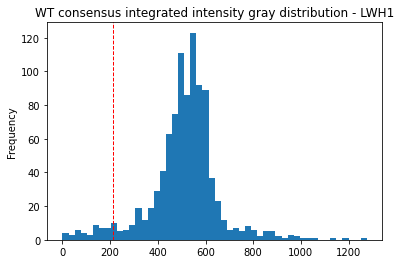

In [170]:
scores_pd = scores.to_pandas()
fig = scores_pd[(scores_pd['db_mut_id'] == 0) &
                (scores_pd['condition_name'] == 'LWH1')].consensus_score.plot(kind='hist', bins=50, title='WT consensus integrated intensity gray distribution - LWH1')

plt.axvline(lower_bound, color='red', linestyle='dashed', linewidth=1)

In [171]:
# Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                            .filter(pl.col("db_mut_id") == 0)
                            .filter(pl.col("consensus_score") <= lower_bound)
                            .select('edge_group')
                            .to_series().unique().to_list())
scores_dropped = scores.filter(pl.col("edge_group").is_in(wt_failures))
scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))
wt_failures

['147.0_55864.0_VUSAPWT6B1',
 '4576.0_4062.0_VUSAPWT2B1',
 '100011481.0_71258.0_VUSAPWT2B1',
 '56532.0_5673.0_VUSAPWT6B1',
 '52634.0_3535.0_VUSAPWT6B1',
 '824.0_70368.0_VUSAPWT1B2',
 '56442.0_3535.0_VUSAPWT6B1',
 '4623.0_9905.0_VUSAPWT1B2',
 '56446.0_55864.0_VUSAPWT6B1',
 '2260.0_5673.0_VUSAPWT2B1',
 '4569.0_3192.0_VUSAPWT1B2',
 '2706.0_6137.0_VUSAPWT1B2',
 '13662.0_7630.0_VUSAPWT1B2',
 '13600.0_70497.0_VUSAPWT1B1',
 '55647.0_12132.0_VUSAPWT1B2',
 '824.0_71206.0_VUSAPWT1B2',
 '55664.0_3192.0_VUSAPWT1B2',
 '13118.0_3670.0_VUSAPWT1B2',
 '6197.0_3192.0_VUSAPWT1B2',
 '13662.0_6983.0_VUSAPWT1B2',
 '6759.0_52920.0_VUSAPWT2B1',
 '824.0_8514.0_VUSAPWT1B2',
 '7439.0_3878.0_VUSAPWT1B2',
 '3148.0_71191.0_VUSAPWT6B1',
 '11621.0_5673.0_VUSAPWT6B1',
 '824.0_13597.0_VUSAPWT1B2',
 '446.0_4862.0_VUSAPWT6B1',
 '3878.0_3878.0_VUSAPWT1B2',
 '2304.0_7634.0_VUSAPWT1B2',
 '252.0_1668.0_VUSAPWT1B2',
 '100067219.0_53657.0_VUSAPWT1B2',
 '100067219.0_70497.0_VUSAPWT1B1',
 '100069191.0_54308.0_VUSAPWT1B1',
 '5540

In [172]:
# write out results
scores.write_csv(f"{outputs_dir}/3_automated_qaqc_consensus_scores.csv")

In [173]:
# normalize scores using WT as reference
normalized_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

# First, sum adjusted scores across conditions for each variant
summed_scores = normalized_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    pl.col("adjusted_score").sum().alias("summed_score")
)

# Get WT scores (db_mut_id == 0) for normalization
wt_scores = summed_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "summed_score"
]).rename({"summed_score": "wt_summed_score"})

# Join variant scores with their corresponding WT scores
normalized_scores = summed_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"
).with_columns(
    (pl.col("summed_score") / pl.col("wt_summed_score")).alias("normalized_score")
).filter(
    pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference
)

In [174]:
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,summed_score,wt_summed_score,normalized_score
i64,i64,i64,str,f64,f64,f64
53886,6983,216119,"""VUSAPWT1B2""",674.166364,989.90492,0.681042
439,52920,2662,"""VUSAPWT6B1""",1501.067602,1674.740919,0.896298
55664,10122,0,"""VUSAPWT1B2""",1572.25015,1572.25015,1.0
6534,8420,216656,"""VUSAPWT1B2""",921.458185,1038.474206,0.887319
100011278,13939,204120,"""VUSAPWT1B2""",1274.608877,1947.773909,0.654393
…,…,…,…,…,…,…
11288,3180,0,"""VUSAPWT1B2""",648.279424,648.279424,1.0
2920,2920,214394,"""VUSAPWT1B2""",955.205577,574.980517,1.661283
100011278,4870,215298,"""VUSAPWT1B2""",1033.341872,1905.987975,0.542156


In [175]:
# normalize scores using WT as reference
normalized_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

# First, sum adjusted scores across conditions for each variant
summed_scores = normalized_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    pl.col("adjusted_score").sum().alias("summed_adjusted_score")
)

# Get WT scores (db_mut_id == 0) for normalization
wt_scores = summed_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "summed_adjusted_score"
]).rename({"summed_adjusted_score": "wt_summed_score"})

# Join variant scores with their corresponding WT scores
normalized_scores = summed_scores.join(
    wt_scores, 
    on=["ad_orf_id", "db_orf_id", "retest_batch"], 
    how="left"
).with_columns(
    (pl.col("summed_adjusted_score") / pl.col("wt_summed_score")).alias("normalized_score")
).filter(
    pl.col("wt_summed_score").is_not_null()  # Only keep variants that have a WT reference
).select([
    "ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch", 
    "summed_adjusted_score", "wt_summed_score", "normalized_score"
]).rename({
    "summed_adjusted_score": "adjusted_score"  # Rename back to adjusted_score for consistency
})

normalized_scores = normalized_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

In [176]:
# cast all to same format
normalized_scores = normalized_scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

normalized_scores = normalized_scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
normalized_scores = normalized_scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")


# Filter to only keep interactions where both ad and db are confirmed
normalized_scores = normalized_scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1")
)
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,adjusted_score,wt_summed_score,normalized_score,assay_id,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class
i64,i64,i64,str,f64,f64,f64,str,str,str,f64,f64
3753,5896,0,"""VUSAPWT1B2""",591.266023,591.266023,1.0,"""1""","""1""","""1""",null,null
13850,71001,205676,"""VUSAPWT6B1""",1674.504092,1788.335908,0.936348,"""6""","""1""","""1""",1.0,1.0
13628,4062,0,"""VUSAPWT2B1""",683.974644,683.974644,1.0,"""2""","""1""","""1""",null,null
55351,5066,0,"""VUSAPWT1B2""",683.80819,683.80819,1.0,"""1""","""1""","""1""",null,null
3818,4723,201725,"""VUSAPWT2B1""",49.858171,142.266014,0.350457,"""2""","""1""","""1""",1.0,1.0
…,…,…,…,…,…,…,…,…,…,…,…
13003,5424,0,"""VUSAPWT6B1""",1574.07521,1574.07521,1.0,"""6""","""1""","""1""",null,null
71963,2713,200856,"""VUSAPWT6B1""",1735.061619,2612.802714,0.664061,"""6""","""1""","""1""",1.0,1.0
1863,52920,2686,"""VUSAPWT1B1""",1826.22882,1621.828469,1.126031,"""1""","""1""","""1""",1.0,1.0


In [177]:
# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

normalized_scores = normalized_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,adjusted_score,wt_summed_score,normalized_score,assay_id,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,ad_symbol
i64,i64,i64,str,f64,f64,f64,str,str,str,f64,f64,str
3753,5896,0,"""VUSAPWT1B2""",591.266023,591.266023,1.0,"""1""","""1""","""1""",null,null,"""C1orf50"""
13850,71001,205676,"""VUSAPWT6B1""",1674.504092,1788.335908,0.936348,"""6""","""1""","""1""",1.0,1.0,"""CSN2"""
13628,4062,0,"""VUSAPWT2B1""",683.974644,683.974644,1.0,"""2""","""1""","""1""",null,null,"""KLRC1"""
55351,5066,0,"""VUSAPWT1B2""",683.80819,683.80819,1.0,"""1""","""1""","""1""",null,null,"""TP53BP2"""
3818,4723,201725,"""VUSAPWT2B1""",49.858171,142.266014,0.350457,"""2""","""1""","""1""",1.0,1.0,"""PSMC5"""
…,…,…,…,…,…,…,…,…,…,…,…,…
13003,5424,0,"""VUSAPWT6B1""",1574.07521,1574.07521,1.0,"""6""","""1""","""1""",null,null,"""SH2D1B"""
71963,2713,200856,"""VUSAPWT6B1""",1735.061619,2612.802714,0.664061,"""6""","""1""","""1""",1.0,1.0,"""MBD3L1"""
1863,52920,2686,"""VUSAPWT1B1""",1826.22882,1621.828469,1.126031,"""1""","""1""","""1""",1.0,1.0,"""STAM2"""


In [178]:
# Append metadata and write out file
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
})

normalized_scores = normalized_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,adjusted_score,wt_summed_score,normalized_score,assay_id,seq_ad,seq_db,db_sequenced,db_sequence_confirmation_class,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,f64,f64,f64,str,str,str,f64,f64,str,str,str,str,str,str,str,f64,f64,str
3753,5896,0,"""VUSAPWT1B2""",591.266023,591.266023,1.0,"""1""","""1""","""1""",null,null,"""C1orf50""","""AHCY""",null,null,"""ENSG00000101444""",null,null,null,null,"""AHCY"""
13850,71001,205676,"""VUSAPWT6B1""",1674.504092,1788.335908,0.936348,"""6""","""1""","""1""",1.0,1.0,"""CSN2""","""UBQLN2""","""Pro509Ser""","""1525C>T""","""ENSG00000188021""","""CEGS2""","""4_VUS""",0.000014,1.0,"""UBQLN2_Pro509Ser"""
13628,4062,0,"""VUSAPWT2B1""",683.974644,683.974644,1.0,"""2""","""1""","""1""",null,null,"""KLRC1""","""PLP1""",null,null,"""ENSG00000123560""",null,null,null,null,"""PLP1"""
55351,5066,0,"""VUSAPWT1B2""",683.80819,683.80819,1.0,"""1""","""1""","""1""",null,null,"""TP53BP2""","""BAG3""",null,null,"""ENSG00000151929""",null,null,null,null,"""BAG3"""
3818,4723,201725,"""VUSAPWT2B1""",49.858171,142.266014,0.350457,"""2""","""1""","""1""",1.0,1.0,"""PSMC5""","""TPM1""","""Glu23Gln""","""67G>C""","""ENSG00000140416""","""CEGS2""","""4_VUS""",null,1.0,"""TPM1_Glu23Gln"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
13003,5424,0,"""VUSAPWT6B1""",1574.07521,1574.07521,1.0,"""6""","""1""","""1""",null,null,"""SH2D1B""","""BLK""",null,null,"""ENSG00000136573""",null,null,null,null,"""BLK"""
71963,2713,200856,"""VUSAPWT6B1""",1735.061619,2612.802714,0.664061,"""6""","""1""","""1""",1.0,1.0,"""MBD3L1""","""MLH1""","""Asp304Gly""","""911A>G""","""ENSG00000076242""","""CEGS2""","""3_Conflicting""",6.8405e-7,1.0,"""MLH1_Asp304Gly"""
1863,52920,2686,"""VUSAPWT1B1""",1826.22882,1621.828469,1.126031,"""1""","""1""","""1""",1.0,1.0,"""STAM2""","""LITAF""","""Pro39Ser""","""115C>T""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,1.0,"""LITAF_Pro39Ser"""


In [179]:
# Remove cases where WT gave no signal at all. eg wt_summed_score == 0
normalized_scores = normalized_scores.filter(pl.col("wt_summed_score") > 0)

    

In [180]:
normalized_scores.write_csv(f"{outputs_dir}/4_automated_normalized_consensus_scores.csv")